Разделить набор данных по погрузкам на тренировочную и тестовую выборки в соотношении 8:2.  
Используя библиотеку sklearn.linear_model обучить модель логистической регрессии.  
Вывести полученные веса.   
Предсказать  вероятность  принадлежности к классу для  каждого наблюдения.   
На тренировочной и  тестовой  выборках  оценить  качество построенной модели, сделать выводы.   
Выявить, где модель ошибается, проанализировать полученные ошибки.   
Вывести график с величиной отступа по каждому наблюдению (отдельно для тренировочной и тестовой выборок).  

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

In [2]:
df = pd.read_excel('orders_short_v3.xlsx')

In [3]:
df = df.drop('Unnamed: 0', axis='columns')

In [29]:
no = ['Идентификатор погрузки', 'Результат', 'Идентификатор переноса', 'Код назначения', 'Код отправления']
numeric = [i for i in df.select_dtypes(include='number').columns if i not in no]

In [6]:
X = df[numeric]
y = df['Результат']

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train) 
X_test_scaled = sc.transform(X_test)       

In [8]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [31]:
pd.DataFrame({'признаки': numeric, 'веса':model.coef_[0]})

,признаки,веса
0,версия погрузки,7.833191
1,Количество вагонов,-0.084792
2,Контрибуция,-0.020393
3,Длительность жизни,-0.207089
4,Время до отправки,0.275572
5,Количество редакций после отправки,1.451490
6,Количество отмен,-5.967438
7,Количество переносов,-3.261913
8,Среднее время между редакциями,0.042836
9,Длительность афтершока,1.228863


In [ ]:
test_probs = model.predict_proba(X_test_scaled)[:, 1]
train_probs = model.predict_proba(X_train_scaled)[:, 1]

In [ ]:
test_preds = model.predict(X_test_scaled)
train_preds = model.predict(X_train_scaled)

In [ ]:
print(f"Test: min = {test_probs.min():.3f}, max = {test_probs.max():.4f}, mean = {test_probs.mean():.3f}")
print(f"Train: min = {train_probs.min():.3f}, max = {train_probs.max():.4f}, mean = {train_probs.mean():.3f}")

Train: min = 0.035, max = 1.0000, mean = 0.573
Test: min = 0.039, max = 1.0000, mean = 0.576


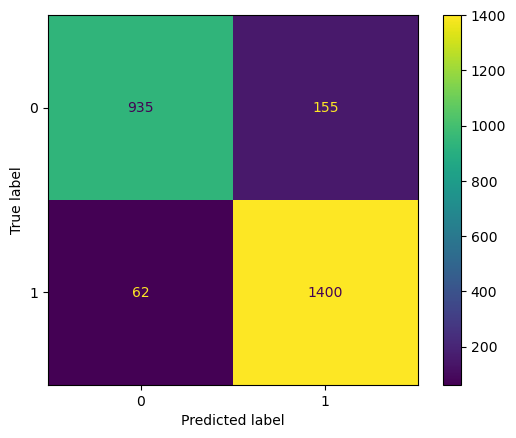

In [36]:
ConfusionMatrixDisplay.from_predictions(y_train, train_preds)

In [39]:
print(f"Accuracy: {accuracy_score(y_train, train_preds):.3f}")
print(f"ROC-AUC:  {roc_auc_score(y_train, train_probs):.3f}")
print(classification_report(y_train, train_preds, target_names=['Класс 0', 'Класс 1']))

Accuracy: 0.915
ROC-AUC:  0.924
              precision    recall  f1-score   support

     Класс 0       0.94      0.86      0.90      1090
     Класс 1       0.90      0.96      0.93      1462

    accuracy                           0.91      2552
   macro avg       0.92      0.91      0.91      2552
weighted avg       0.92      0.91      0.91      2552



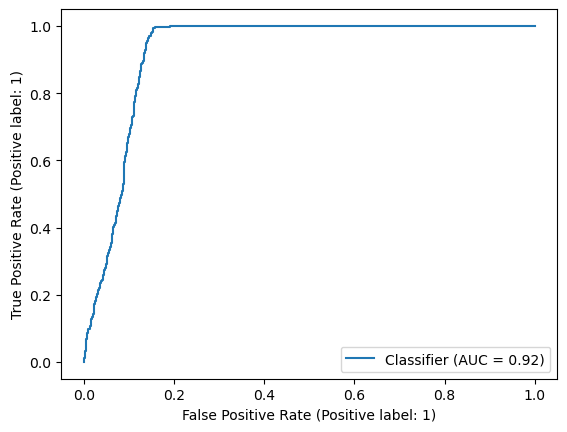

In [40]:
RocCurveDisplay.from_predictions(y_train, train_probs)

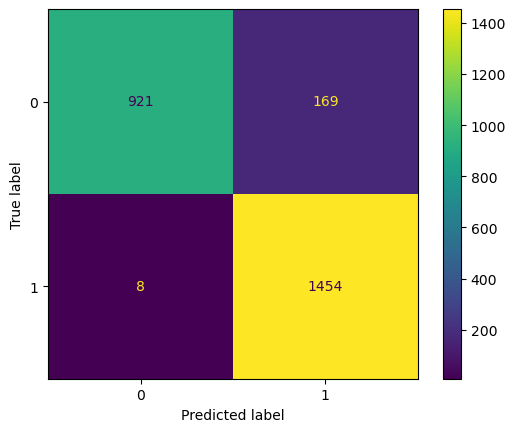

In [42]:
ConfusionMatrixDisplay.from_predictions(y_train, [1 if _ > 0.38 else 0 for _ in train_probs])

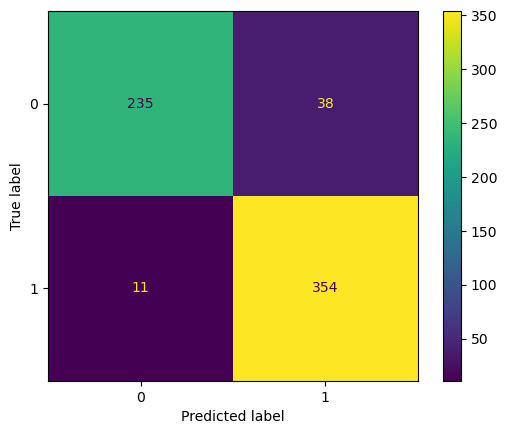

In [43]:
ConfusionMatrixDisplay.from_predictions(y_test, test_preds)

In [45]:
print(f"Accuracy: {accuracy_score(y_test, test_preds):.3f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, test_probs):.3}")
print(classification_report(y_test, test_preds, target_names=['Класс 0', 'Класс 1']))

Accuracy: 0.923
ROC-AUC:  0.931
              precision    recall  f1-score   support

     Класс 0       0.96      0.86      0.91       273
     Класс 1       0.90      0.97      0.94       365

    accuracy                           0.92       638
   macro avg       0.93      0.92      0.92       638
weighted avg       0.93      0.92      0.92       638



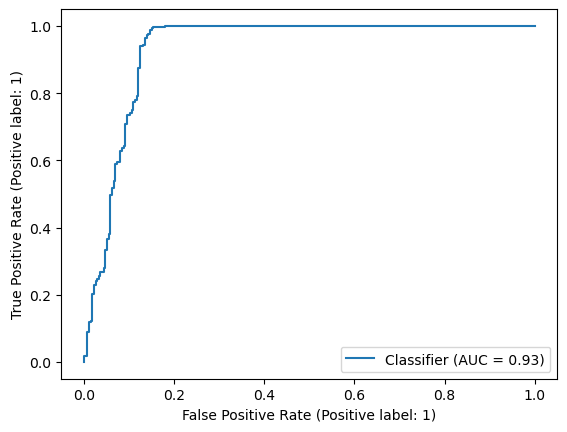

In [46]:
RocCurveDisplay.from_predictions(y_test, test_probs)

In [48]:
error = y_test != test_preds
if error.any():
    print(f"\nОшибок: {error.sum()}/{len(y_test)} ({error.mean():.2%})")
    print("\nСредние значения признаков:")
    print(pd.concat({'На ошибках': X_test[error].mean(),
                     'На верных': X_test[~error].mean()}, axis=1).round(3))


Ошибок: 49/638 (7.68%)

Средние значения признаков:
                                    На ошибках    На верных
версия погрузки                          4.612        3.664
Количество вагонов                      34.000       31.299
Контрибуция                         803590.816  1098742.431
Длительность жизни                      14.213        8.251
Время до отправки                        8.628       10.997
Количество редакций после отправки       1.592        0.829
Количество отмен                         3.612        2.696
Количество переносов                     0.694        0.618
Среднее время между редакциями           3.987        2.752
Длительность афтершока                   3.668       -4.345


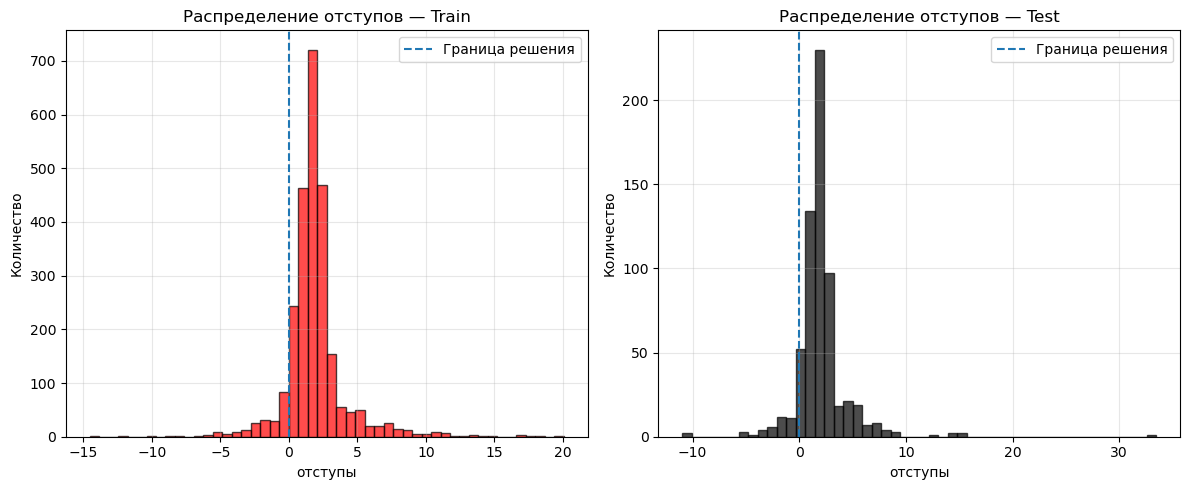


Отступы:
Train: mean=1.914, median=1.696, отрицательных=217 (8.50%)
Test: mean=2.032, median=1.815, отрицательных=49 (7.68%)


In [53]:
y_bin = {k: np.where(v == 0, -1, 1) for k, v in [('tr', y_train), ('te', y_test)]}
margin = {k: y_bin[k] * (X @ model.coef_[0] + model.intercept_[0]) 
          for k, X in [('tr', X_train_scaled), ('te', X_test_scaled)]}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, (k, color, title) in enumerate([('tr', 'red', 'Train'), ('te', 'black', 'Test')]):
    m = margin[k]
    axes[i].hist(m, bins=50, color=color, alpha=0.7, edgecolor='black')
    axes[i].axvline(0, ls='--', label='Граница решения')
    axes[i].set_title(f'Распределение отступов — {title}')
    axes[i].set_xlabel('отступы'); axes[i].set_ylabel('Количество')
    axes[i].legend(); axes[i].grid(alpha=0.3)

plt.tight_layout(); plt.show()

print(f"\nОтступы:")
for k, name in [('tr', 'Train'), ('te', 'Test')]:
    m = margin[k]
    print(f"{name}: mean={m.mean():.3f}, median={np.median(m):.3f}, "
          f"отрицательных={(m<0).sum()} ({(m<0).mean():.2%})")